# Монгол Улсын хүн амын шилжилт хөдөлгөөн: аймгуудын харьцуулалт
## Мини төсөл: Монголын нээлттэй өгөгдлийн EDA · 1-р баг

| № | Гишүүн | Үүрэг | Файл |
|---|---|---|---|
| 1 | Цэцэглэн | Функц хөгжүүлэгч | сан: `cleaning.py`, `stats.py` |
| 2 | Батука | Багийн ахлагч, сангийн ахлагч | сан: `plots.py`, `extra.py`, `__init__.py`, `pyproject.toml`, PyPI |
| 3 | Маргад | Шинжээч | шинжилгээ: `analysis.ipynb`, `figures/` |
| 4 | Батбилгүүн | Дүгнэгч, танилцуулга | шинжилгээ: `README.md`, танилцуулга |

### Асуулт
> **Бүртгэлтэй шилжилт хөдөлгөөн аймгууд ба Улаанбаатарын хооронд хэрхэн хуваарилагдаж байна вэ, энэ дүр зураг цаг хугацааны явцад хэрхэн өөрчлөгдөж байна вэ?**

Яагаад сонирхолтой вэ: «Бүгд Улаанбаатарыг зорьдог» гэсэн таамаг олонд байдаг. Үүнийг албан ёсны өгөгдлөөр шалгана — хаашаа хамгийн олон хүн ирж байна, хаанаас явж байна, ирсэн нь явснаас хаана давж байна, энэ он тутам хэрхэн өөрчлөгдсөн бэ.

### Өгөгдөл
- Эх сурвалж: ҮСХ, [1212.mn](https://www.1212.mn), хүснэгт `DT_NSO_0300_040V1` — шилжин ирсэн, шилжин явсан хүний тоо, аймаг, нийслэлээр, жилээр. Татаж авсан: 2026.10.14.
- Файл: `data/migration_raw.csv` (өөрчлөлтгүй анхны татац). Нэгж — хүн (бүртгэлтэй шилжилт).
- Зөвхөн энэ нэг хүснэгт; хүн амын тоо ашиглахгүй тул «1000 хүнд ногдох» үзүүлэлт тооцохгүй.

### Хэрэгсэл
Google Colab, pandas, NumPy, Matplotlib, Seaborn ба багийн сан **`aiaa-eda-team1`** (`pip install`). Энэ notebook-д `def` байхгүй — бүх функц сангаас ирнэ.

### Notebook-ийн бүтэц (удирдамжийн дагуу)
1. `pip install` — санг суулгах
2. `import aiaa_eda_team1 as et`, өгөгдөл upload
3. Танилцах ба цэвэрлэгээ: `et.missing_report`, `et.strip_text_columns`, `et.drop_duplicate_rows`, `et.split_totals`, `et.flows_wide_to_long`, `et.mark_both_zero_as_missing`, `et.iqr_outliers`
4. Тоон шинжилгээ: `et.rank_table`, `et.rank_gap`, `et.basic_stats`, `et.group_rate`, `et.period_summary`, `et.national_balance`
5. График: `et.plot_bar`, `et.plot_grouped_bar`, `et.plot_line`, `et.plot_small_multiples`, `et.plot_hist`, `et.plot_box` → `figures/`
6. Шалгалт, дүгнэлт, `migration_clean.csv` ба `figures.zip`

Ажиллуулах: *Runtime → Restart session and run all*; файл сонгох цонх гарахад `migration_raw.csv`-г оруулна.

## 1. Санг суулгах

**Код юу хийдэг вэ:** багийн сан `aiaa-eda-team1`-ийг PyPI-аас суулгана. Хэрэв сан аль хэдийн суусан бол (жишээ нь хөгжүүлэгчийн компьютер дээр `pip install -e .`) дахин суулгахгүй.
**Яагаад:** удирдамжийн шаардлага — бүх функц сангаас ирнэ, notebook-д `def` бичихгүй. PyPI-д байршаагүй үед доорх тайлбар мөрийг ашиглана.

In [1]:
import importlib.util

if importlib.util.find_spec("aiaa_eda_team1") is None:
    !pip install -q aiaa-eda-team1
    # PyPI-д хараахан байршаагүй бол GitHub-аас:
    # !pip install -q git+https://github.com/tsetseglenb0310-spec/aiaa-eda-team1.git

## 2. Санг импортлох, өгөгдөл оруулах

**Код юу хийдэг вэ:** `et` нэрээр санг импортлож, хувилбарыг хэвлэнэ; `figures/` хавтас үүсгэнэ; `migration_raw.csv` байхгүй бол Colab-ийн файл оруулах цонх нээнэ.

In [2]:
import os
import pandas as pd
import aiaa_eda_team1 as et

print("aiaa_eda_team1 хувилбар:", et.__version__)

FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)
SOURCE = "Эх сурвалж: ҮСХ, 1212.mn — DT_NSO_0300_040V1. Нэгж: хүн"

RAW_FILE = "migration_raw.csv"
if not os.path.exists(RAW_FILE) and os.path.exists(os.path.join("data", RAW_FILE)):
    RAW_FILE = os.path.join("data", RAW_FILE)          # GitHub repo бүтцээр ажиллуулах үед
if not os.path.exists(RAW_FILE):
    from google.colab import files                       # Colab: файл сонгох цонх
    uploaded = files.upload()

df_raw = pd.read_csv(RAW_FILE)      # анхны татац — өөрчлөхгүй
print("Ачаалсан файл:", RAW_FILE, "| хэмжээ (мөр, багана):", df_raw.shape)

aiaa_eda_team1 хувилбар: 0.1.0
Ачаалсан файл: data\migration_raw.csv | хэмжээ (мөр, багана): (56, 45)


## 3. Танилцах ба цэвэрлэгээ

### 3.1 Танилцах
**Асуулт:** файлд үнэндээ юу байна — мөр, багана, он, үзүүлэлт, дутуу утга, давхардал.
**Код юу хийдэг вэ:** `head`, `dtypes`, `value_counts` — pandas-ийн стандарт үзлэг; `et.missing_report` — багана бүрийн дутуу утгын тайлан.

In [3]:
display(df_raw.head())
print(df_raw.dtypes.value_counts())
year_cols = [c for c in df_raw.columns if c.isdigit()]
print("Он-баганын тоо:", len(year_cols), "| хүрээ:", min(year_cols), "–", max(year_cols))
print()
print(df_raw["Үзүүлэлт"].value_counts())
print()
print(df_raw["Бүс"].value_counts().head(6))

,Үзүүлэлт,Бүс,2025,2024,2023,2022,2021,2020,2019,2018,...,1992,1991,1990,1989,1988,1987,1986,1985,1984,1983
0,Шилжин ирсэн,Улсын дүн,59447,62627,56152,54824,44023,59563,31366,31429,...,66611,81780,37933,39818,41317,26875,18165,14863,18067,10732
1,Шилжин ирсэн,Баруун бүс,2235,6530,2133,1589,2059,3824,2036,2635,...,12571,16920,5614,6074,5356,2864,2019,2767,2772,2272
2,Шилжин ирсэн,Баян-Өлгий,248,276,213,179,206,163,154,214,...,4339,3623,2206,1012,1425,833,539,583,549,90
3,Шилжин ирсэн,Говь-Алтай,282,556,295,191,316,365,390,485,...,1854,1093,726,1182,981,233,273,557,258,276
4,Шилжин ирсэн,Завхан,505,1318,429,342,560,1081,431,697,...,3621,7826,927,1126,515,864,225,637,660,83


int64    43
str       2
Name: count, dtype: int64
Он-баганын тоо: 43 | хүрээ: 1983 – 2025

Үзүүлэлт
Шилжин ирсэн    28
Шилжин явсан    28
Name: count, dtype: int64

Бүс
Улаанбаатар    4
Улсын дүн      2
Баруун бүс     2
Баян-Өлгий     2
Говь-Алтай     2
Завхан         2
Name: count, dtype: int64


**Код юу хийдэг вэ:** `et.missing_report(df_raw)` багана бүрийн дутуу утгын тоо ба хувийг нэг хүснэгтэд гаргана (Гишүүн 1-ийн функц, `cleaning.py`).
**Яагаад:** `isnull().sum()`-ыг 45 баганад тус тусад нь харахаас нэг тайлан илүү ойлгомжтой; дараа нь бусад өгөгдөлд ч дахин ашиглана.

In [4]:
# et.missing_report — дутуу утгын тайлан (Гишүүн 1-ийн функц)
report = et.missing_report(df_raw)
print("Нийт дутуу утга:", int(report["missing"].sum()))
display(report.head())

Нийт дутуу утга: 0


,column,dtype,missing,missing_pct
0,Үзүүлэлт,str,0,0.0
1,Бүс,str,0,0.0
2,2025,int64,0,0.0
3,2024,int64,0,0.0
4,2023,int64,0,0.0


**Үр дүн:** 56 мөр × 45 багана — өргөн хэлбэр (он баганаар), 43 он (1983–2025), бүх он-багана `int64`. Дутуу утга 0. Үзүүлэлт хоёр: «Шилжин ирсэн», «Шилжин явсан». Харин **Улаанбаатар 4 удаа**, «Улсын дүн» ба 4 бүсийн дүн нутгуудтай хамт байна — үүнийг цэвэрлэнэ.

### 3.2 Цэвэрлэгээ
**Асуудал → үйлдэл:**
1. Нэрийн захын зай → `et.strip_text_columns`
2. Бүрэн давхардсан мөр (Улаанбаатар хоёр удаа) → `et.drop_duplicate_rows`
3. Улс ба бүсийн дүн нутгуудын дунд → `et.split_totals`
4. Он баганаар (wide) → нэг мөр = нутаг × он (long) → `et.flows_wide_to_long`
5. Говьсүмбэрийн эхний онуудад хоёр урсгал тэг → `et.mark_both_zero_as_missing`

**Яагаад энэ дараалал:** зайг эхлээд арилгахгүй бол давхардал олдохгүй; дүнг салгахгүй бол аймгуудын нийлбэр хоёр дахин өснө.

In [5]:
TOTAL_ROWS = ["Улсын дүн", "Баруун бүс", "Хангайн бүс", "Төвийн бүс", "Зүүн бүс"]
IN_LABEL, OUT_LABEL = "Шилжин ирсэн", "Шилжин явсан"

df, n_strip = et.strip_text_columns(df_raw)
print("1) Захын зай арилгасан нүд:", n_strip)

df, n_dups = et.drop_duplicate_rows(df)
print("2) Устгасан давхардал:", n_dups, "| одоо:", df.shape)

territories, totals = et.split_totals(df, "Бүс", TOTAL_ROWS)
print("3) Нутгийн мөр:", len(territories), "| дүнгийн мөр:", len(totals),
      "| давтагдашгүй нутаг:", territories["Бүс"].nunique())

# Цэвэрлэгээгүй бол: 2025 оны "Шилжин ирсэн" БҮХ мөрийн нийлбэр (давхардал, дүнтэй)
naive_sum_in = int(df_raw[df_raw["Үзүүлэлт"] == IN_LABEL]["2025"].sum())
official_in = int(totals[(totals["Бүс"] == "Улсын дүн") & (totals["Үзүүлэлт"] == IN_LABEL)]["2025"].iloc[0])
print(f"   Цэвэрлэгээгүй нийлбэр {et.fmt(naive_sum_in)} vs албан ёсны {et.fmt(official_in)} "
      f"({naive_sum_in / official_in:.1f} дахин их)")

1) Захын зай арилгасан нүд: 0
2) Устгасан давхардал: 2 | одоо: (54, 45)
3) Нутгийн мөр: 44 | дүнгийн мөр: 10 | давтагдашгүй нутаг: 22
   Цэвэрлэгээгүй нийлбэр 178 341 vs албан ёсны 59 447 (3.0 дахин их)


**Код юу хийдэг вэ:** `et.flows_wide_to_long` өргөн хүснэгтийг урт болгоно — он бүрт нэг жижиг хүснэгт үүсгэж, ирсэн ба явсныг нутгийн нэрээр (`dict` + `map`) тааруулж, `pd.concat`-аар нэгтгэнэ. Дараа нь `et.mark_both_zero_as_missing` хоёр урсгал зэрэг тэг мөрүүдэд NaN тавина.
**Яагаад:** урт хүснэгт (нэг мөр = нутаг × он) `groupby`, `sort_values`, графикт тохиромжтой; merge/melt ашиглахгүй.

In [6]:
mig_long = et.flows_wide_to_long(territories, "Үзүүлэлт", "Бүс", IN_LABEL, OUT_LABEL)
print("4) Урт хүснэгт:", mig_long.shape, "= нутаг", mig_long["aimag"].nunique(), "× он", mig_long["year"].nunique())

mig_long, n_zero, zero_rows = et.mark_both_zero_as_missing(mig_long, ["in_mig", "out_mig"])
print("5) Хоёр урсгал зэрэг тэг → NaN:", n_zero, "мөр")
display(zero_rows)
display(mig_long.head())

4) Урт хүснэгт: (946, 4) = нутаг 22 × он 43
5) Хоёр урсгал зэрэг тэг → NaN: 8 мөр


,aimag,year,in_mig,out_mig
215,Говьсүмбэр,1983,0,0
216,Говьсүмбэр,1984,0,0
217,Говьсүмбэр,1985,0,0
218,Говьсүмбэр,1986,0,0
219,Говьсүмбэр,1987,0,0
220,Говьсүмбэр,1988,0,0
221,Говьсүмбэр,1989,0,0
222,Говьсүмбэр,1990,0,0


,aimag,year,in_mig,out_mig
0,Архангай,1983,1958.0,3281.0
1,Архангай,1984,1775.0,4942.0
2,Архангай,1985,527.0,274.0
3,Архангай,1986,223.0,1008.0
4,Архангай,1987,1252.0,2496.0


**Үр дүн:** 2 давхардал устгаж 54 мөр үлдлээ; 44 нутгийн мөр, 10 дүнгийн мөр тусдаа. Урт хүснэгт 946 мөр = 22 нутаг × 43 он. Говьсүмбэр 1983–1990 онд хоёр урсгал яг 0 (8 мөр) — тэр үед тусдаа бүртгэгдээгүй тул «өгөгдөлгүй» гэж тэмдэглэсэн, тэг шилжилт гэж үзээгүй. Алдааны үнэ: цэвэрлэгээгүй нийлбэр 178 341 — албан ёсны 59 447-аас 3.0 дахин их.

### 3.3 Цэвэр шилжилт ба outlier
**Томьёо:** `net_migration = in_mig − out_mig`. Эерэг — ирсэн нь олон; сөрөг — явсан нь олон. Энэ бол *бүртгэлтэй шилжилтийн* шинж, хүн амын тооны өөрчлөлт биш.
**Код юу хийдэг вэ:** цэвэр шилжилтийг тооцож, бүсийн багана нэмж (`et.add_region`), сүүлийн оны хэсгийг авч, `et.iqr_outliers`-ээр 1.5·IQR дүрмийн хэт утгыг олно.

In [7]:
mig_long["net_migration"] = mig_long["in_mig"] - mig_long["out_mig"]
mig_long = et.add_region(mig_long)                       # аймаг → бүс
LATEST_YEAR = int(mig_long["year"].max())                # сүүлийн оныг кодоор
latest = mig_long[mig_long["year"] == LATEST_YEAR].copy()
print("Сүүлийн он:", LATEST_YEAR, "| нутаг:", len(latest))

out = et.iqr_outliers(latest, "net_migration")
print(f"1.5·IQR хил: [{out['low']:.0f}; {out['high']:.0f}] → outlier {out['n_outliers']}:")
display(out["rows"][["aimag", "in_mig", "out_mig", "net_migration"]])

Сүүлийн он: 2025 | нутаг: 22
1.5·IQR хил: [-3462; 1546] → outlier 2:


,aimag,in_mig,out_mig,net_migration
730,Улаанбаатар,32030.0,12996.0,19034.0
945,Өмнөговь,4179.0,2032.0,2147.0


**Үр дүн:** 2025 онд 1.5·IQR дүрмээр outlier хоёр — Улаанбаатар, Өмнөговь (хил [-3 462; 1 546]). Улаанбаатар бусдаас арав дахин хол; Өмнөговь аймгуудын дундах дээд outlier. Эдгээрийг устгахгүй — бодит нутаг, алдаа биш.

## 4. Тоон шинжилгээ

### 4.1 Эрэмбэ: хаашаа ирж, хаанаас явж байна (2025)
**Код юу хийдэг вэ:** `et.rank_table` — нэг баганаар эрэмбэлсэн хүснэгт; `et.rank_gap` — ирсний байр ба цэвэр шилжилтийн байрын зөрүү.

In [8]:
rank_in = et.rank_table(latest, "in_mig")
rank_out = et.rank_table(latest, "out_mig")
rank_net = et.rank_table(latest, "net_migration", extra_cols=["in_mig", "out_mig"])
display(rank_in.head(6))
display(rank_out.head(6))
display(rank_net)

n_positive = int((latest["net_migration"] > 0).sum())
n_negative = int((latest["net_migration"] < 0).sum())
share_ub = latest.loc[latest["aimag"] == "Улаанбаатар", "in_mig"].iloc[0] / latest["in_mig"].sum() * 100
print(f"{LATEST_YEAR}: эерэг цэвэр шилжилт {n_positive} нутагт, сөрөг {n_negative} нутагт; "
      f"Улаанбаатарын эзлэх хувь ирсэнд {share_ub:.0f} %")

gap = et.rank_gap(latest, "in_mig", "net_migration")
display(gap.head(5))

,rank,aimag,in_mig
0,1,Улаанбаатар,32030.0
1,2,Өмнөговь,4179.0
2,3,Дархан-Уул,3875.0
3,4,Орхон,3246.0
4,5,Төв,2230.0
5,6,Сэлэнгэ,2048.0


,rank,aimag,out_mig
0,1,Улаанбаатар,12996.0
1,2,Сэлэнгэ,3707.0
2,3,Төв,3509.0
3,4,Архангай,2939.0
4,5,Хөвсгөл,2908.0
5,6,Орхон,2840.0


,rank,aimag,in_mig,out_mig,net_migration
0,1,Улаанбаатар,32030.0,12996.0,19034.0
1,2,Өмнөговь,4179.0,2032.0,2147.0
2,3,Дархан-Уул,3875.0,2584.0,1291.0
3,4,Орхон,3246.0,2840.0,406.0
4,5,Дорноговь,1838.0,2046.0,-208.0
5,6,Говьсүмбэр,528.0,821.0,-293.0
6,7,Баян-Өлгий,248.0,697.0,-449.0
7,8,Дундговь,674.0,1497.0,-823.0
8,9,Сүхбаатар,610.0,1501.0,-891.0
9,10,Дорнод,697.0,1631.0,-934.0


2025: эерэг цэвэр шилжилт 4 нутагт, сөрөг 18 нутагт; Улаанбаатарын эзлэх хувь ирсэнд 54 %


,aimag,in_mig,net_migration,rank_a,rank_b,gap
0,Сэлэнгэ,2048.0,-1659.0,6,19,13
1,Өвөрхангай,1173.0,-1647.0,9,18,9
2,Хөвсгөл,730.0,-2178.0,12,21,9
3,Төв,2230.0,-1279.0,5,13,8
4,Архангай,645.0,-2294.0,15,22,7


**Үр дүн:** ирсэнээр Улаанбаатар 32 030 (54 %), дараа нь Өмнөговь (4 179), Дархан-Уул (3 875), Орхон (3 246). Явсанаар мөн нийслэл (12 996), аймгуудаас Сэлэнгэ (3 707), Төв, Архангай. Цэвэр шилжилт эерэг зөвхөн **4 нутагт**: Улаанбаатар (+19 034), Өмнөговь (+2 147), Дархан-Уул (+1 291), Орхон (+406); 18 аймагт сөрөг, хамгийн их гарах урсгал Архангай (-2 294).
**Хариулт:** ирсэн олон ≠ цэвэр шилжилт их — Сэлэнгэ ирсэнээр 6-р, цэвэр шилжилтээр 19-р байр.

### 4.2 Тайлбарлах статистик: нутгууд хэр ялгаатай вэ
**Код юу хийдэг вэ:** `et.basic_stats` (NumPy: дундаж, медиан, std ddof=1, квартиль, IQR) — бүх 22 нутагт ба Улаанбаатаргүй 21 аймагт.

In [9]:
aimags_only = latest[latest["aimag"] != "Улаанбаатар"]
stats_table = pd.DataFrame({
    "22 нутаг (Улаанбаатартай)": et.basic_stats(latest["net_migration"]),
    "21 аймаг (Улаанбаатаргүй)": et.basic_stats(aimags_only["net_migration"]),
}).round(0)
display(stats_table)
print("21 аймгаас эерэг цэвэр шилжилттэй:", int((aimags_only["net_migration"] > 0).sum()))

,22 нутаг (Улаанбаатартай),21 аймаг (Улаанбаатаргүй)
n,22.0,21.0
mean,0.0,-906.0
median,-1172.0,-1241.0
std,4386.0,1103.0
min,-2294.0,-2294.0
q1,-1584.0,-1613.0
q3,-332.0,-449.0
iqr,1252.0,1164.0
max,19034.0,2147.0


21 аймгаас эерэг цэвэр шилжилттэй: 3


**Үр дүн:** 22 нутгийн дундаж 0 (2020 оноос улсын ирсэн = явсан тул нийлбэр тэг), медиан -1 172. 21 аймгийн медиан **-1 241**, IQR 1 164 (-1 613…-449), зөвхөн 3 аймаг эерэг. Ердийн аймаг хүн алдаж байна; дунджийг тэг «болгож» байгаа нь ганц Улаанбаатар.

### 4.3 Хувь ба хугацааны хураангуй: group_rate, period_summary
**Код юу хийдэг вэ:** `net_positive` (0/1) багана үүсгээд `et.group_rate` — бүс бүрт 2020–2025 оны нутаг-жилүүдийн хэдэн хувь нь эерэг байсныг; `et.period_summary` — нутаг бүрийн дундаж, мин, макс, эерэг жилийн тоо.
**Яагаад 2020 оноос:** доорх 4.4-д харуулснаар зөвхөн 2020 оноос улсын бүртгэл бүрэн харьцуулагдана.

In [10]:
mig_long["net_positive"] = (mig_long["net_migration"] > 0).astype(int)
recent = mig_long[mig_long["year"] >= 2020]

rate_by_region = et.group_rate(recent, "region", "net_positive")
display(rate_by_region)

summary = et.period_summary(mig_long, "aimag", "net_migration", since=2020)
display(summary)
always_positive = summary[summary["years_positive"] == summary["years_total"]]["aimag"].tolist()
never_positive = summary[summary["years_positive"] == 0]["aimag"].tolist()
print("Бүх жил эерэг:", always_positive)
print("Нэг ч удаа эерэг болоогүй:", len(never_positive), "нутаг")

,region,n,rate
0,Улаанбаатар,6,1.000
1,Төвийн бүс,42,0.143
2,Хангайн бүс,36,0.056
3,Баруун бүс,30,0.000
4,Зүүн бүс,18,0.000


,aimag,mean,min,max,years_positive,years_total
0,Улаанбаатар,22004.0,14291.0,30419.0,6,6
1,Өмнөговь,656.0,-433.0,2147.0,4,6
2,Говьсүмбэр,-244.0,-419.0,-82.0,0,6
3,Дархан-Уул,-399.0,-1950.0,1291.0,2,6
4,Баян-Өлгий,-457.0,-568.0,-251.0,0,6
5,Орхон,-457.0,-1755.0,406.0,2,6
6,Сүхбаатар,-630.0,-891.0,-331.0,0,6
7,Дорноговь,-693.0,-1294.0,-205.0,0,6
8,Дорнод,-735.0,-1234.0,-341.0,0,6
9,Дундговь,-905.0,-1134.0,-671.0,0,6


Бүх жил эерэг: ['Улаанбаатар']
Нэг ч удаа эерэг болоогүй: 18 нутаг


**Үр дүн:** 2020–2025 онд эерэг цэвэр шилжилттэй нутаг-жилийн хувь: Улаанбаатар 100 %, Төвийн бүс 14 %, Хангайн бүс 6 %, Баруун ба Зүүн бүс 0 %. Жил бүр эерэг байсан нь ганц нутаг — Улаанбаатар; 18 нутагт нэг ч удаа эерэг болоогүй — гарах урсгал тогтвортой.

### 4.4 Харьцуулах боломж: улсын ирсэн = явсан уу?
**Код юу хийдэг вэ:** `et.national_balance` — «Улсын дүн» мөрөөр он бүрийн ирсэн − явсан. Улс дотор нэг нүүдэл = нэг явсан + нэг ирсэн тул бүрэн бүртгэлтэй үед зөрүү 0 байх ёстой.

In [11]:
national = et.national_balance(totals, "Үзүүлэлт", "Бүс", "Улсын дүн", IN_LABEL, OUT_LABEL)
equal_years = national[national["diff"] == 0]["year"].tolist()
FIRST_EQUAL = min(equal_years)
print("Ирсэн = явсан байсан онууд:", equal_years)
display(national[national["year"] >= 2015])

Ирсэн = явсан байсан онууд: [2020, 2021, 2022, 2023, 2024, 2025]


,year,in_total,out_total,diff
32,2015,53912,53684,228
33,2016,50683,52189,-1506
34,2017,37443,32806,4637
35,2018,31429,29810,1619
36,2019,31366,31219,147
37,2020,59563,59563,0
38,2021,44023,44023,0
39,2022,54824,54824,0
40,2023,56152,56152,0
41,2024,62627,62627,0


**Үр дүн:** зөвхөн **2020 оноос** улсын хэмжээнд ирсэн = явсан; өмнө нь зөрдөг (1993: -34 395). Тиймээс 2020 оноос өмнөх онуудтай харьцуулахдаа болгоомжтой; зөрүүний шалтгааныг өгөгдлөөр тогтоох боломжгүй.

## 5. График (бүгд `figures/`-д хадгалагдана)

**Код юу хийдэг вэ:** сангийн графикийн функцуудыг дуудна; `path=` өгсөн тул файл хадгалагдана. График бүрт он, нэгж, эх сурвалж бичигдэнэ.

### 5.1 Хаашаа ирж байна, хаана цэвэр шилжилт эерэг вэ (2025)

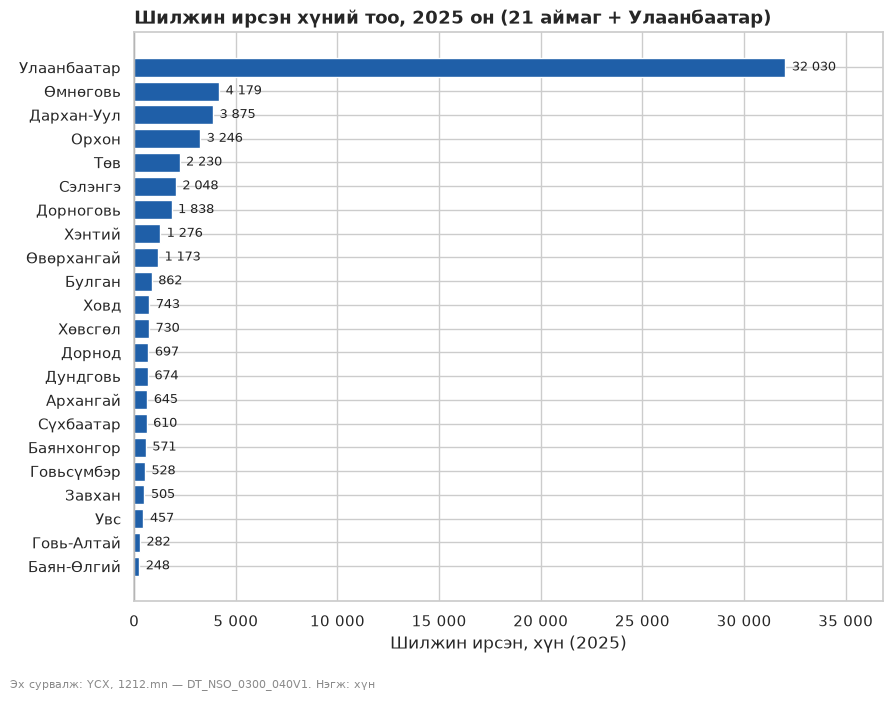

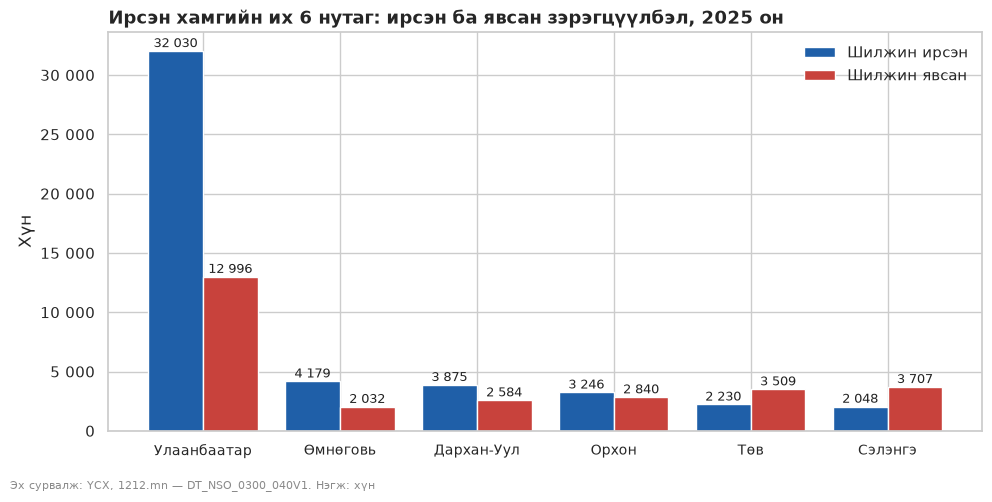

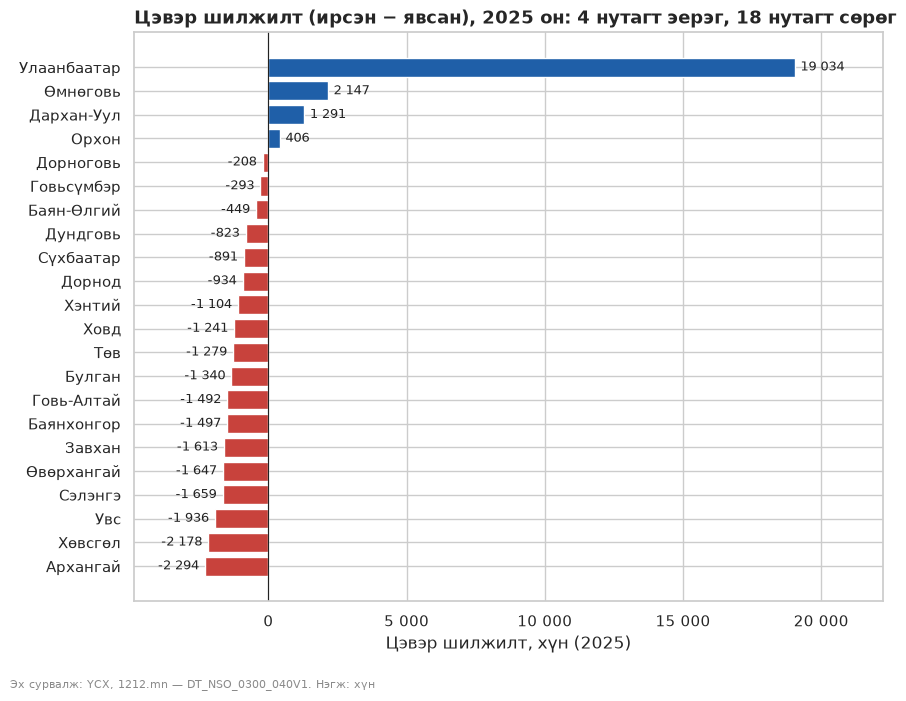

In [12]:
et.plot_bar(latest, "aimag", "in_mig", path=f"{FIG_DIR}/01_in_ranking_{LATEST_YEAR}.png",
            title=f"Шилжин ирсэн хүний тоо, {LATEST_YEAR} он (21 аймаг + Улаанбаатар)",
            xlabel=f"Шилжин ирсэн, хүн ({LATEST_YEAR})", source=SOURCE)

leaders = latest.sort_values("in_mig", ascending=False).head(6)
et.plot_grouped_bar(leaders, "aimag", ["in_mig", "out_mig"], labels=["Шилжин ирсэн", "Шилжин явсан"],
                    path=f"{FIG_DIR}/02_leaders_in_vs_out_{LATEST_YEAR}.png",
                    title=f"Ирсэн хамгийн их 6 нутаг: ирсэн ба явсан зэрэгцүүлбэл, {LATEST_YEAR} он", source=SOURCE)

et.plot_bar(latest, "aimag", "net_migration", path=f"{FIG_DIR}/03_net_ranking_{LATEST_YEAR}.png",
            title=f"Цэвэр шилжилт (ирсэн − явсан), {LATEST_YEAR} он: {n_positive} нутагт эерэг, {n_negative} нутагт сөрөг",
            xlabel=f"Цэвэр шилжилт, хүн ({LATEST_YEAR})", source=SOURCE, color_by_sign=True);

**Тайлбар:** 01 — нийслэл бусдаас 8 дахин их; 02 — Төв, Сэлэнгэд явсан нь ирснээс олон; 03 — 4 нутагт эерэг, 18-д сөрөг.

### 5.2 Динамик: Улаанбаатар ба гурван замнал
**Сонголтын дүрэм (кодоор):** Улаанбаатар + 2025 оны цэвэр шилжилт хамгийн их аймаг + хамгийн бага аймаг. Панел бүр өөрийн масштабтай — нийслэлийн утга арав дахин их.

Оргил: 2004 (41 592) | 1990 оноос хойш хамгийн бага: 2018 (6 568) | 2020–2025 ирсэн 26–40 мян./жил, дундаж цэвэр +22 004
Сонгогдсон нутгууд: ['Улаанбаатар', 'Өмнөговь', 'Архангай']


,aimag,mean,min,max,years_positive,years_total
0,Улаанбаатар,22004.0,14291.0,30419.0,6,6
1,Өмнөговь,656.0,-433.0,2147.0,4,6
21,Архангай,-2100.0,-2567.0,-1363.0,0,6


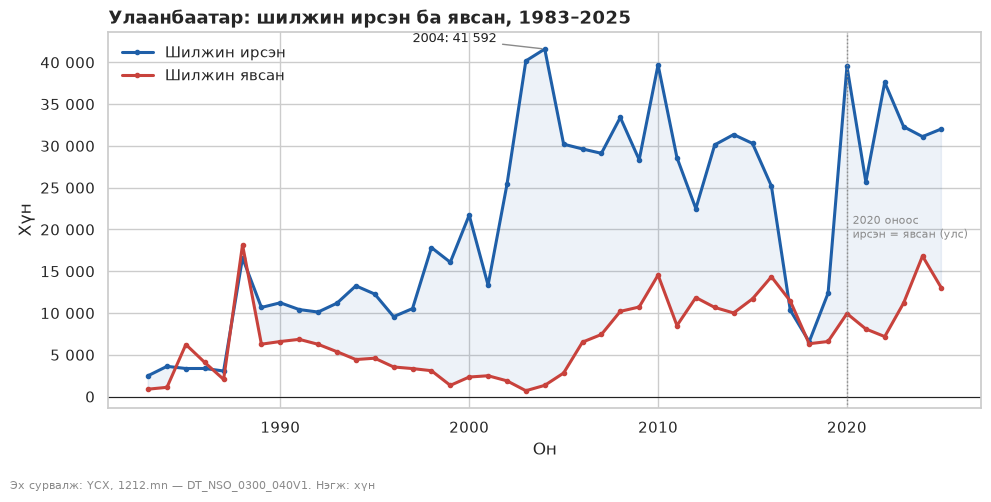

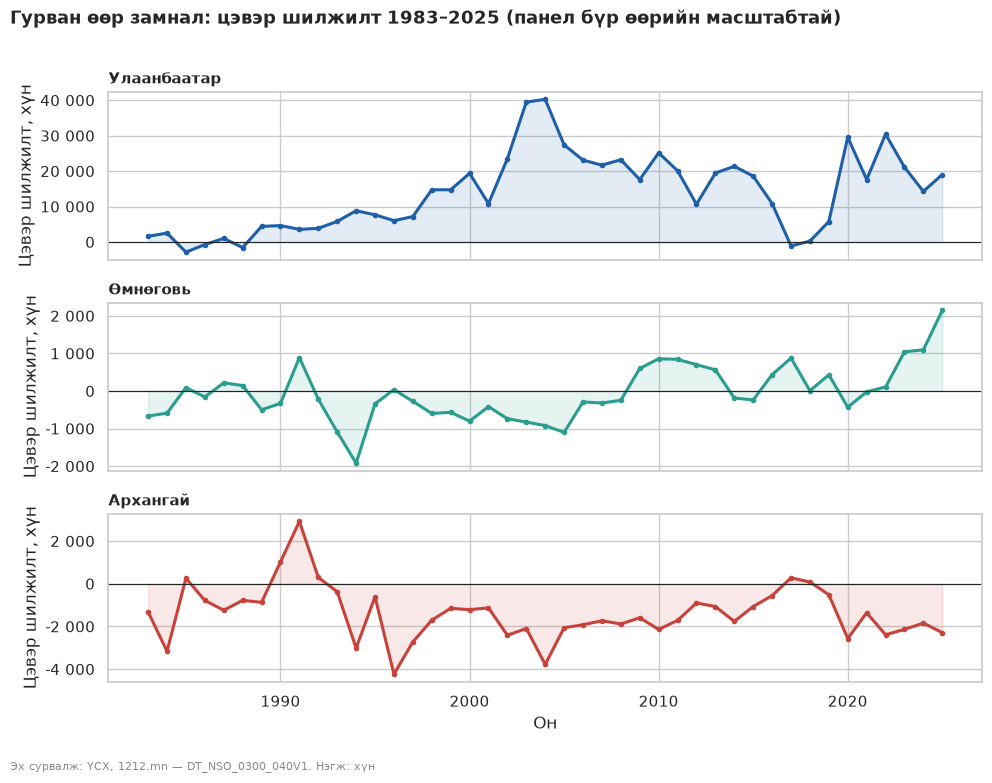

In [13]:
ub = mig_long[mig_long["aimag"] == "Улаанбаатар"]
et.plot_line(ub, "year", ["in_mig", "out_mig"], labels=["Шилжин ирсэн", "Шилжин явсан"], path=f"{FIG_DIR}/04_ub_in_out_{ub['year'].min()}_{LATEST_YEAR}.png",
             title=f"Улаанбаатар: шилжин ирсэн ба явсан, {ub['year'].min()}–{LATEST_YEAR}", ylabel="Хүн", source=SOURCE,
             vline=FIRST_EQUAL, vline_label=f"{FIRST_EQUAL} оноос\nирсэн = явсан (улс)",
             annotate_max=True, fill_between=("in_mig", "out_mig"))

ub_peak_year = int(ub.loc[ub["in_mig"].idxmax(), "year"])
ub_peak_in = int(ub["in_mig"].max())
ub_modern = ub[ub["year"] >= 1990]
ub_low_year = int(ub_modern.loc[ub_modern["in_mig"].idxmin(), "year"])
ub_low_in = int(ub_modern["in_mig"].min())
ub_recent = ub[ub["year"] >= FIRST_EQUAL]
print(f"Оргил: {ub_peak_year} ({et.fmt(ub_peak_in)}) | 1990 оноос хойш хамгийн бага: {ub_low_year} ({et.fmt(ub_low_in)}) | "
      f"{FIRST_EQUAL}–{LATEST_YEAR} ирсэн {ub_recent['in_mig'].min()/1000:.0f}–{ub_recent['in_mig'].max()/1000:.0f} мян./жил, "
      f"дундаж цэвэр {et.fmt(ub_recent['net_migration'].mean(), sign=True)}")

best_aimag = aimags_only.loc[aimags_only["net_migration"].idxmax(), "aimag"]
worst_aimag = aimags_only.loc[aimags_only["net_migration"].idxmin(), "aimag"]
selected = ["Улаанбаатар", best_aimag, worst_aimag]
print("Сонгогдсон нутгууд:", selected)
trio = mig_long[mig_long["aimag"].isin(selected)]
et.plot_small_multiples(trio, "year", "net_migration", "aimag", order=selected,
                        path=f"{FIG_DIR}/05_three_trajectories.png",
                        title=f"Гурван өөр замнал: цэвэр шилжилт {mig_long['year'].min()}–{LATEST_YEAR} (панел бүр өөрийн масштабтай)",
                        ylabel="Цэвэр шилжилт, хүн", source=SOURCE)
display(summary[summary["aimag"].isin(selected)])

**Тайлбар:** 04 — ирсэн бараг үргэлж явснаас олон; оргил 2004 (41 592), 1990 оноос хойш хамгийн бага 2018 (6 568), 2020 оноос 26–40 мян./жил. 2018–2017 оны уналт ба 2020 оны үсрэлт бүртгэлийн өөрчлөлттэй давхцана — шалтгааныг өгөгдөлгүйгээр нэрлэхгүй. 05 — Улаанбаатар тогтвортой орох урсгал (+22 004), Өмнөговь сүүлийн жилүүдэд эерэг (+656, 6 жилээс 4), Архангай тогтвортой гарах урсгал (-2 100).

### 5.3 Тархалт ба харьцуулах боломж

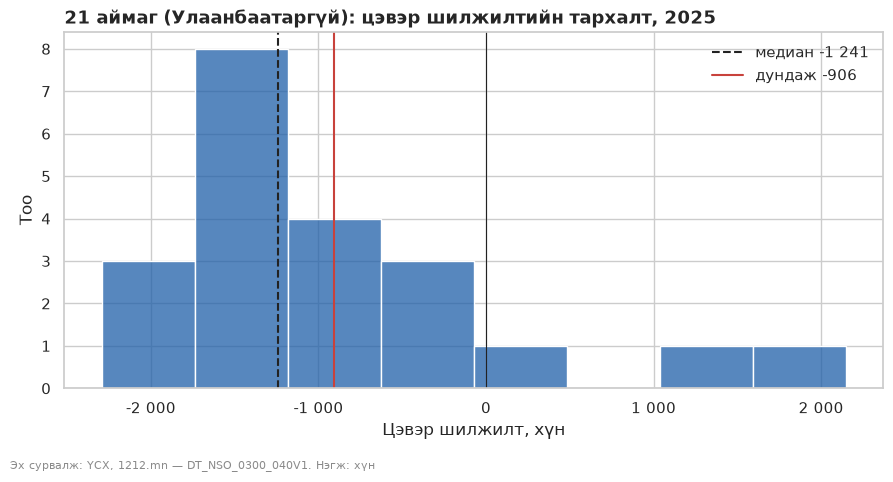

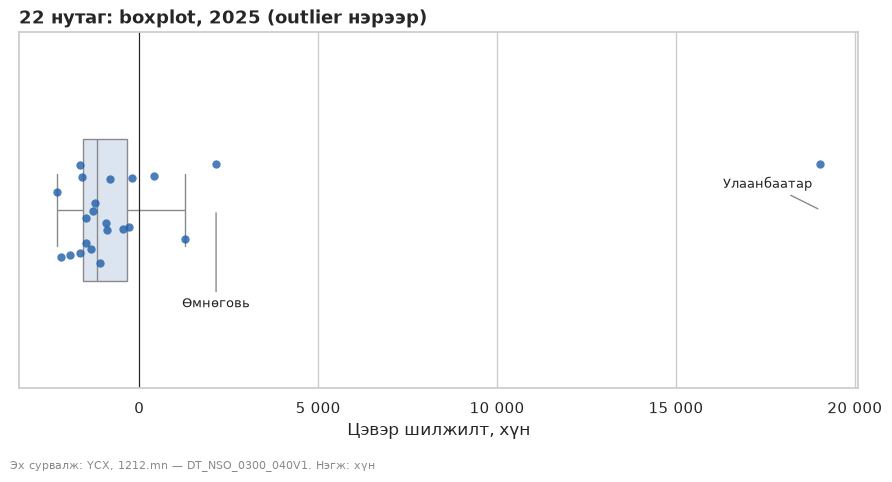

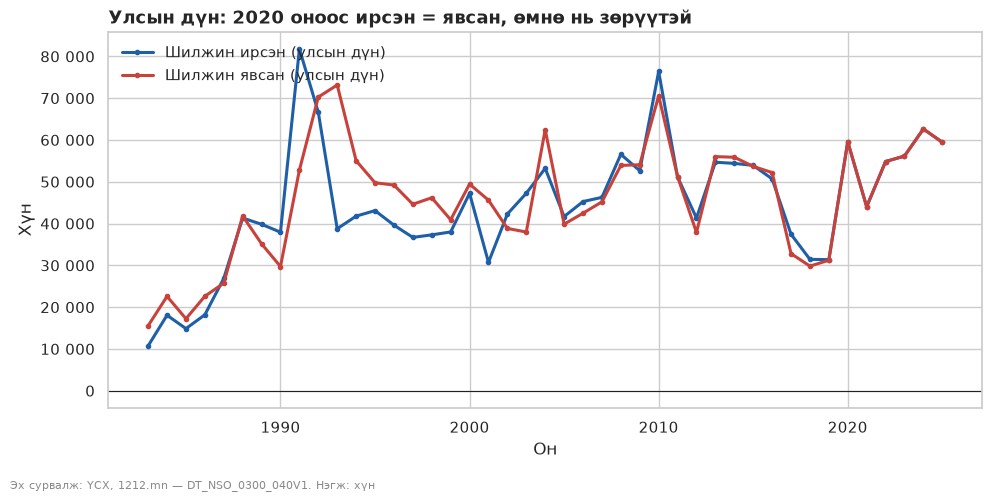

In [14]:
et.plot_hist(aimags_only, "net_migration", bins=8, path=f"{FIG_DIR}/06_net_hist_{LATEST_YEAR}.png",
             title=f"21 аймаг (Улаанбаатаргүй): цэвэр шилжилтийн тархалт, {LATEST_YEAR}",
             xlabel="Цэвэр шилжилт, хүн", source=SOURCE)
et.plot_box(latest, "net_migration", path=f"{FIG_DIR}/07_net_box_{LATEST_YEAR}.png",
            title=f"22 нутаг: boxplot, {LATEST_YEAR} (outlier нэрээр)", xlabel="Цэвэр шилжилт, хүн", source=SOURCE,
            label_col="aimag", label_rows=out["rows"])
et.plot_line(national, "year", ["in_total", "out_total"], labels=["Шилжин ирсэн (улсын дүн)", "Шилжин явсан (улсын дүн)"], path=f"{FIG_DIR}/08_national_in_out.png",
             title=f"Улсын дүн: {FIRST_EQUAL} оноос ирсэн = явсан, өмнө нь зөрүүтэй", ylabel="Хүн", source=SOURCE);

**Тайлбар:** 06 — ердийн аймаг -1 241 орчим; 07 — Улаанбаатар ба Өмнөговь outlier; 08 — 2020 оноос хоёр шугам давхцана.

## 6. Шалгалт, дүгнэлт, хадгалах

### 6.1 Автомат шалгалт
**Код юу хийдэг вэ:** `et.consistency_checks` — оны бүрэн байдал, түлхүүрийн давтагдашгүй байдал, хоёр урсгал, нутгуудын нийлбэр = улсын дүн (он, урсгал бүр), бүсийн нийлбэр = бүсийн дүн, давхар тоолол байхгүй, 22 нутаг.

In [15]:
checks, details = et.consistency_checks(mig_long, totals, "Үзүүлэлт", "Бүс", "Улсын дүн", IN_LABEL, OUT_LABEL,
                                        TOTAL_ROWS, et.REGION_OF, n_expected=22)
for name, ok in checks.items():
    print(f"[{'OK' if ok else 'FAIL'}] {name}")
print("Бүгд OK:", all(checks.values()), "| улсын дүнтэй зөрсөн он:", len(details["national_mismatch"]),
      "| бүсээр зөрсөн:", len(details["region_mismatch"]))

[OK] Нутаг бүрт бүх он байна
[OK] aimag+year түлхүүр давтагдахгүй
[OK] Хоёр урсгал зэрэг бий эсвэл зэрэг байхгүй
[OK] Нутгуудын нийлбэр = улсын дүн (бүх он, хоёр урсгал)
[OK] Бүсийн аймгуудын нийлбэр = бүсийн дүн
[OK] Дүнгийн мөр урт хүснэгтэд ороогүй
[OK] Яг 22 нутаг
Бүгд OK: True | улсын дүнтэй зөрсөн он: 0 | бүсээр зөрсөн: 0


**Үр дүн:** бүх 7 шалгалт амжилттай (OK). Цэвэрлэгээ хүнийг алдаагүй, давхарлаагүй.

### 6.2 Дүгнэлт (хувьсагчаас хэвлэнэ — гараар бичсэн тоо байхгүй)

In [16]:
ub_row = latest[latest["aimag"] == "Улаанбаатар"].iloc[0]
positive_names = rank_net[rank_net["net_migration"] > 0]["aimag"].tolist()
worst_row = rank_net.iloc[-1]

print(f"1. {LATEST_YEAR} онд Улаанбаатар ирсэнээр ч ({et.fmt(ub_row['in_mig'])}, улсын {share_ub:.0f} %), "
      f"цэвэр шилжилтээр ч ({et.fmt(ub_row['net_migration'], sign=True)}) тэргүүлнэ.")
print(f"2. Эерэг цэвэр шилжилт зөвхөн {n_positive} нутагт: {', '.join(positive_names)}. "
      f"{n_negative} аймагт сөрөг; хамгийн их гарах урсгал — {worst_row['aimag']} ({et.fmt(worst_row['net_migration'], sign=True)}).")
print(f"3. {FIRST_EQUAL}–{LATEST_YEAR} онд цэвэр шилжилт жил бүр эерэг байсан нь {', '.join(always_positive)}; "
      f"{len(never_positive)} нутагт нэг ч удаа эерэг болоогүй.")
print(f"4. Нийслэлийн ирсэн: оргил {ub_peak_year} ({et.fmt(ub_peak_in)}), уналт {ub_low_year} ({et.fmt(ub_low_in)}), "
      f"{FIRST_EQUAL} оноос {ub_recent['in_mig'].min()/1000:.0f}–{ub_recent['in_mig'].max()/1000:.0f} мян./жил.")
print(f"5. Гурван замнал: Улаанбаатар (орох урсгал), {best_aimag} (сүүлийн жилүүдэд орох), {worst_aimag} (тогтвортой гарах).")

1. 2025 онд Улаанбаатар ирсэнээр ч (32 030, улсын 54 %), цэвэр шилжилтээр ч (+19 034) тэргүүлнэ.
2. Эерэг цэвэр шилжилт зөвхөн 4 нутагт: Улаанбаатар, Өмнөговь, Дархан-Уул, Орхон. 18 аймагт сөрөг; хамгийн их гарах урсгал — Архангай (-2 294).
3. 2020–2025 онд цэвэр шилжилт жил бүр эерэг байсан нь Улаанбаатар; 18 нутагт нэг ч удаа эерэг болоогүй.
4. Нийслэлийн ирсэн: оргил 2004 (41 592), уналт 2018 (6 568), 2020 оноос 26–40 мян./жил.
5. Гурван замнал: Улаанбаатар (орох урсгал), Өмнөговь (сүүлийн жилүүдэд орох), Архангай (тогтвортой гарах).


### Хязгаарлалт
- **Зөвхөн бүртгэлтэй шилжилт.** Сөрөг цэвэр шилжилт нь хүн ам цөөрснийг нотлохгүй: төрөлт, нас баралт, бүртгэлгүй нүүдэл өгөгдөлд байхгүй.
- **Абсолют тоо.** Хүн амын тоогүйгээр нэг хүнд ногдох эрчмийг харьцуулахгүй.
- **Харьцуулах боломж.** 2020 оноос өмнө улсын ирсэн ≠ явсан; Говьсүмбэр 1983–1990 онд тусдаа бүртгэгдээгүй.
- **Тайлбарлах шинжилгээ.** *Юу* болж байгааг харуулсан, *яагаад* гэдгийг биш; шалтгааныг таамаглахгүй. Статистик тест хэрэглээгүй — 22 нутаг бол бүх нийт, түүвэр биш.

### 6.3 Цэвэрлэсэн CSV ба figures.zip
**Код юу хийдэг вэ:** урт хүснэгтийг `migration_clean.csv`-д хадгална; `figures/`-ийг `figures.zip` болгоно. Colab-д тайлбар мөрүүдийг нээж татаж авна, дараа нь шинжилгээний repo-д оруулна.

In [17]:
import shutil

CLEAN_FILE = "migration_clean.csv"
mig_long[["aimag", "region", "year", "in_mig", "out_mig", "net_migration"]].to_csv(CLEAN_FILE, index=False, encoding="utf-8")
print("Хадгалсан:", CLEAN_FILE, "| мөр:", len(mig_long))

zip_path = shutil.make_archive("figures", "zip", FIG_DIR)
print("Архив:", zip_path, "| графикууд:", sorted(os.listdir(FIG_DIR)))

# Colab-аас татаж авах — тайлбарыг арилгана:
# from google.colab import files
# files.download(CLEAN_FILE)
# files.download("figures.zip")

Хадгалсан: migration_clean.csv | мөр: 946
Архив: C:\Users\USER\OneDrive\Desktop\ИИ инженер\Багийн төсөл\migration-analysis\figures.zip | графикууд: ['01_in_ranking_2025.png', '02_leaders_in_vs_out_2025.png', '03_net_ranking_2025.png', '04_ub_in_out_1983_2025.png', '05_three_trajectories.png', '06_net_hist_2025.png', '07_net_box_2025.png', '08_national_in_out.png']


---
Сан: `pip install aiaa-eda-team1` · Бүх функц сангаас, notebook-д `def` байхгүй · Графикууд `figures/`, тайлбар нь шинжилгээний repo-ийн `README.md`-д.